In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile
from pathlib import Path
import copy
import glob 

In [52]:
path = "../data/raw/"
file = "AMF_CA-Ca2_FLUXNET_2000-2010_v1.3_r1.zip"  # will be substituted by container
keep = ["TIMESTAMP_START", "TIMESTAMP_END", "TA_F", "SW_IN_F", "VPD_F", "P_F",
        "NETRAD", "G_F_MDS", "H_F_MDS", "H_F_MDS_QC", "LE_F_MDS", "LE_F_MDS_QC",
        "NEE_VUT_REF", "NEE_VUT_REF_QC", "GPP_NT_VUT_REF", "RECO_NT_VUT_REF"]

def unpack_data(path="../data/raw/", keep=keep):
    container_list = sorted(glob.glob(path + "*.zip"))
    dflist = []

    for container in container_list:
        with zipfile.ZipFile(container) as archive:
            names = archive.namelist()
            ds_name = next(name for name in names if "FLUXMET_HH" in name)
            bif_name = next(name for name in names if "_BIF_" in name)
            bif = pd.read_csv(archive.open(bif_name))
            igbp_code = bif.loc[bif["VARIABLE"].eq("IGBP"), "DATAVALUE"].iloc[0]

            dataset = pd.read_csv(
                archive.open(ds_name),
                na_values=[-9999],
                usecols=lambda s: s in keep,
                dtype={"TIMESTAMP_START": str, "TIMESTAMP_END": str},
            )

        dataset["time"] = pd.to_datetime(dataset["TIMESTAMP_START"], format="%Y%m%d%H%M")
        dataset["site"] = ds_name.split("_FLUXNET_FLUXMET_HH")[0]
        dataset["dsname"] = ds_name
        dataset["IGBP"] = igbp_code
        dflist.append(dataset)

    return pd.concat(dflist)

master_df = unpack_data()

### C1. Site Overview
A table with one row per tower: site ID, name, country, IGBP class, latitude, longitude, first and last year, hub, and the data citation. Most of it is in your snapshot CSV. Add a simple map of the five sites (a world map with five points is enough).

In [53]:
# site ID, name, country, IGBP class, latitude, longitude, first and last year, hub, and the data citation
IGBP_CLASSES = {
    "ENF": "Evergreen Needleleaf Forests",
    "EBF": "Evergreen Broadleaf Forests",
    "DNF": "Deciduous Needleleaf Forests",
    "DBF": "Deciduous Broadleaf Forests",
    "MF":  "Mixed Forests",
    "CSH": "Closed Shrublands",
    "OSH": "Open Shrublands",
    "WSA": "Woody Savannas",
    "SAV": "Savannas",
    "GRA": "Grasslands",
    "WET": "Permanent Wetlands",
    "CRO": "Croplands",
    "URB": "Urban and Built-Up Lands",
    "CVM": "Cropland/Natural Vegetation Mosaics",
    "SNO": "Snow and Ice",
    "BSV": "Barren Sparse Vegetation",
    "WAT": "Water Bodies",
                }
countries_dict = {  
                    "CA" : "Canada",
                    "US" : "USA",
                    "FR" : "France",
                    "CN" : "China",
                    "AU" : "Australia"
                }

countries_acronym = master_df["site"].str.split("_").str[-1].str.split("-").str[0]
master_df["country"] = countries_acronym.map(countries_dict)
master_df["IGBP_Class"] = master_df["IGBP"].map(IGBP_CLASSES)

In [54]:
sites_df = (
    master_df.assign(year=master_df["time"].dt.year)
    .groupby("site", as_index=False)
    .agg(
        country=("country", "first"),
        IGBP=("IGBP", "first"),
        IGBP_Class=("IGBP_Class", "first"),
        first_year=("year", "min"),
        last_year=("year", "max"),
    )
    .sort_values("site")
)

snapshot = pd.read_csv("../data/snapshots/fluxnet_shuttle_snapshot_20261113T110345.csv")
sites_df["site_id"] = sites_df["site"].str.split("_").str[-1]

sites_df = sites_df.merge(
    snapshot[["site_id", "location_lat", "location_long",
              "data_hub", "product_citation"]],
    on="site_id",
    how="left",
).rename(columns={
    "location_lat": "latitude",
    "location_long": "longitude",
    "data_hub": "hub",
    "product_citation": "citation",
})

sites_df

,site,country,IGBP,IGBP_Class,first_year,last_year,site_id,latitude,longitude,hub,citation
0,AMF_CA-Ca2,Canada,ENF,Evergreen Needleleaf Forests,2000,2010,CA-Ca2,49.870500,-125.29090,AmeriFlux,"T. Andrew Black (2025), AmeriFlux FLUXNET-1F C..."
1,AMF_US-Bi1,USA,CRO,Croplands,2016,2024,US-Bi1,38.099200,-121.49930,AmeriFlux,"Camilo Rey-Sanchez, Carlos Tianxin Wang, Daphn..."
2,ICOS_FR-Hes,France,DBF,Deciduous Broadleaf Forests,1997,2026,FR-Hes,48.674100,7.06465,ICOS,"Cuntz, M., Joetzjer, E., Aiguier, T., Courtois..."
3,JPF_CN-HaM,China,GRA,Grasslands,2001,2014,CN-HaM,37.607433,101.33200,ICOS,"Du, M., Gu, S., Kato, T., Li, Y., Liang, Z., Z..."
4,TERN_AU-Dry,Australia,SAV,Savannas,2009,2025,AU-Dry,-15.258800,132.37060,TERN,"Beringer, J., Hutley, L., Northwood, M. (2026)..."


In [55]:
import plotly.express as px

fig = px.scatter_geo(
    sites_df,
    lat="latitude",
    lon="longitude",
    hover_name="site_id",
    projection="natural earth",
)
fig.show()



### C2. Data coverage

For each site and year, the share of half hours in which NEE was measured (`NEE_VUT_REF_QC == 0`). Show it as a heat map: sites on the y-axis, years on the x-axis, colour = share measured. Add one sentence: which site and years have the best data?


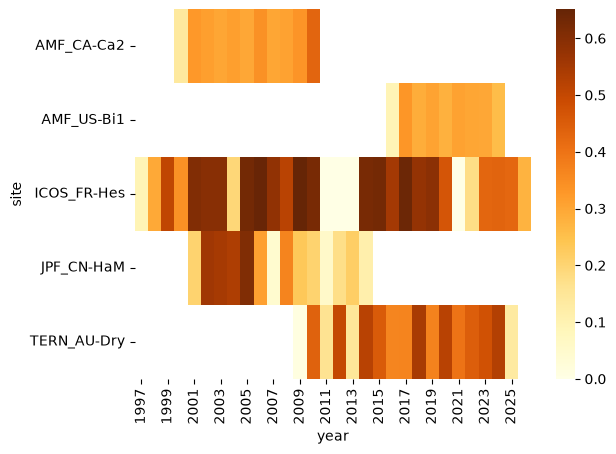

In [56]:
import seaborn as sns

# Share of half-hours with valid NEE data per site
master_df["year"] = master_df["time"].dt.year
sites_QC = (
    master_df
    .groupby(["site","year"], dropna=False)
    .agg(
        share_NEE_VUT_REF=("NEE_VUT_REF_QC", lambda s: (s == 0).mean())
    )
    .reset_index()
)

sites_QC = sites_QC.copy()
sites_qc_wide = sites_QC.pivot_table(  # somehow needed for sns heatmap 🤷‍♂️
    index='site',
    columns='year',
    values='share_NEE_VUT_REF'
)
sns.heatmap(sites_qc_wide, cmap="YlOrBr")
plt.show()

The best data is available for the ICOS-FR_Hes Tower although there is a gap for the years 2011 to 2013


### C3. Summary statistics

A table per site with mean, minimum, maximum and % missing for `TA_F`, `SW_IN_F`, `VPD_F`, `P_F`, `NEE_VUT_REF`, `GPP_NT_VUT_REF`, `RECO_NT_VUT_REF`, `H_F_MDS` and `LE_F_MDS`. Give the units in the column headers. For precipitation, give the mean annual sum instead of the mean.


In [57]:
site_tables = {}

for site, site_df in master_df.groupby("site"):
    rows = []

    for var, unit in var_units.items():
        values = site_df[var]

        if var == "P_F":
            # Summarize annual precipitation totals, not half-hourly values.
            values = site_df.groupby("year")[var].sum(min_count=1)
            variable_label = f"{var} (annual sum, {unit})"
        else:
            variable_label = f"{var} ({unit})"

        rows.append({
            "Variable": variable_label,
            "Mean": values.mean(),
            "Minimum": values.min(),
            "Maximum": values.max(),
            "% missing": site_df[var].isna().mean() * 100,
        })

    site_tables[site] = (
        pd.DataFrame(rows)
        .set_index("Variable")
        .round(2)
    )

# Display one table per site
for site, table in site_tables.items():
    print(site)
    display(table)


AMF_CA-Ca2


,Mean,Minimum,Maximum,% missing
Variable,,,,
TA_F (°C),8.52,-18.14,37.24,0.0
SW_IN_F (W m⁻²),128.10,0.00,1098.00,0.0
VPD_F (kPa),3.38,0.00,49.53,0.0
"P_F (annual sum, mm yr⁻¹)",1145.53,618.46,1439.37,0.0
NEE_VUT_REF (µmol CO₂ m⁻² s⁻¹),1.50,-19.56,29.27,4.8
GPP_NT_VUT_REF (µmol CO₂ m⁻² s⁻¹),2.23,-21.11,31.49,4.8
RECO_NT_VUT_REF (µmol CO₂ m⁻² s⁻¹),3.73,0.10,21.89,4.8
H_F_MDS (W m⁻²),23.81,-325.00,562.70,4.8
LE_F_MDS (W m⁻²),22.37,-91.09,614.80,4.8


AMF_US-Bi1


,Mean,Minimum,Maximum,% missing
Variable,,,,
TA_F (°C),14.81,-5.38,42.83,0.00
SW_IN_F (W m⁻²),220.69,0.00,1138.29,0.00
VPD_F (kPa),7.74,0.00,69.40,0.00
"P_F (annual sum, mm yr⁻¹)",385.33,175.90,500.20,0.00
NEE_VUT_REF (µmol CO₂ m⁻² s⁻¹),0.02,-54.13,25.40,6.34
GPP_NT_VUT_REF (µmol CO₂ m⁻² s⁻¹),5.77,-19.69,63.65,6.34
RECO_NT_VUT_REF (µmol CO₂ m⁻² s⁻¹),5.77,0.00,14.08,6.34
H_F_MDS (W m⁻²),17.12,-362.82,374.90,6.33
LE_F_MDS (W m⁻²),64.55,-41.52,636.83,6.33


ICOS_FR-Hes


,Mean,Minimum,Maximum,% missing
Variable,,,,
TA_F (°C),10.68,-15.44,37.19,1.20
SW_IN_F (W m⁻²),140.32,0.00,1102.66,1.20
VPD_F (kPa),4.36,0.00,54.35,1.20
"P_F (annual sum, mm yr⁻¹)",911.17,396.28,1230.72,1.20
NEE_VUT_REF (µmol CO₂ m⁻² s⁻¹),-1.25,-58.28,43.95,20.06
GPP_NT_VUT_REF (µmol CO₂ m⁻² s⁻¹),4.87,-41.36,66.78,23.93
RECO_NT_VUT_REF (µmol CO₂ m⁻² s⁻¹),3.70,0.00,21.22,23.93
H_F_MDS (W m⁻²),9.40,-289.35,544.72,16.02
LE_F_MDS (W m⁻²),31.02,-129.25,750.30,17.33


JPF_CN-HaM


,Mean,Minimum,Maximum,% missing
Variable,,,,
TA_F (°C),-1.03,-35.57,29.48,0.00
SW_IN_F (W m⁻²),198.54,0.00,1244.20,0.00
VPD_F (kPa),2.74,0.00,30.82,0.00
"P_F (annual sum, mm yr⁻¹)",3047.61,2620.56,3476.88,0.00
NEE_VUT_REF (µmol CO₂ m⁻² s⁻¹),-0.53,-32.50,25.87,18.81
GPP_NT_VUT_REF (µmol CO₂ m⁻² s⁻¹),2.42,-24.61,38.40,29.51
RECO_NT_VUT_REF (µmol CO₂ m⁻² s⁻¹),1.86,0.00,19.45,29.51
H_F_MDS (W m⁻²),23.20,-199.94,490.24,5.47
LE_F_MDS (W m⁻²),30.78,-299.64,499.82,11.11


TERN_AU-Dry


,Mean,Minimum,Maximum,% missing
Variable,,,,
TA_F (°C),27.15,5.87,41.98,0.00
SW_IN_F (W m⁻²),254.48,0.00,1250.00,0.00
VPD_F (kPa),18.84,0.00,75.51,0.00
"P_F (annual sum, mm yr⁻¹)",831.05,373.07,1332.93,0.00
NEE_VUT_REF (µmol CO₂ m⁻² s⁻¹),-1.06,-45.14,38.49,16.40
GPP_NT_VUT_REF (µmol CO₂ m⁻² s⁻¹),3.46,-35.57,45.31,23.16
RECO_NT_VUT_REF (µmol CO₂ m⁻² s⁻¹),2.36,0.00,8.05,23.16
H_F_MDS (W m⁻²),56.86,-148.00,663.00,16.38
LE_F_MDS (W m⁻²),60.79,-50.00,600.00,16.38



### C4. Time series

Aggregate the half-hourly data to daily values yourself and plot daily NEE, GPP and RECO over the whole record, one panel per site.

Unit conversion: 1 µmol CO₂ m⁻² s⁻¹ = 1.0378 g C m⁻² d⁻¹ (× 86 400 s × 12.011 g mol⁻¹ × 10⁻⁶). So a daily mean in µmol m⁻² s⁻¹ × 1.0378 gives g C m⁻² d⁻¹.

Check your aggregation once against the daily `FLUXMET_DD` file for one site.



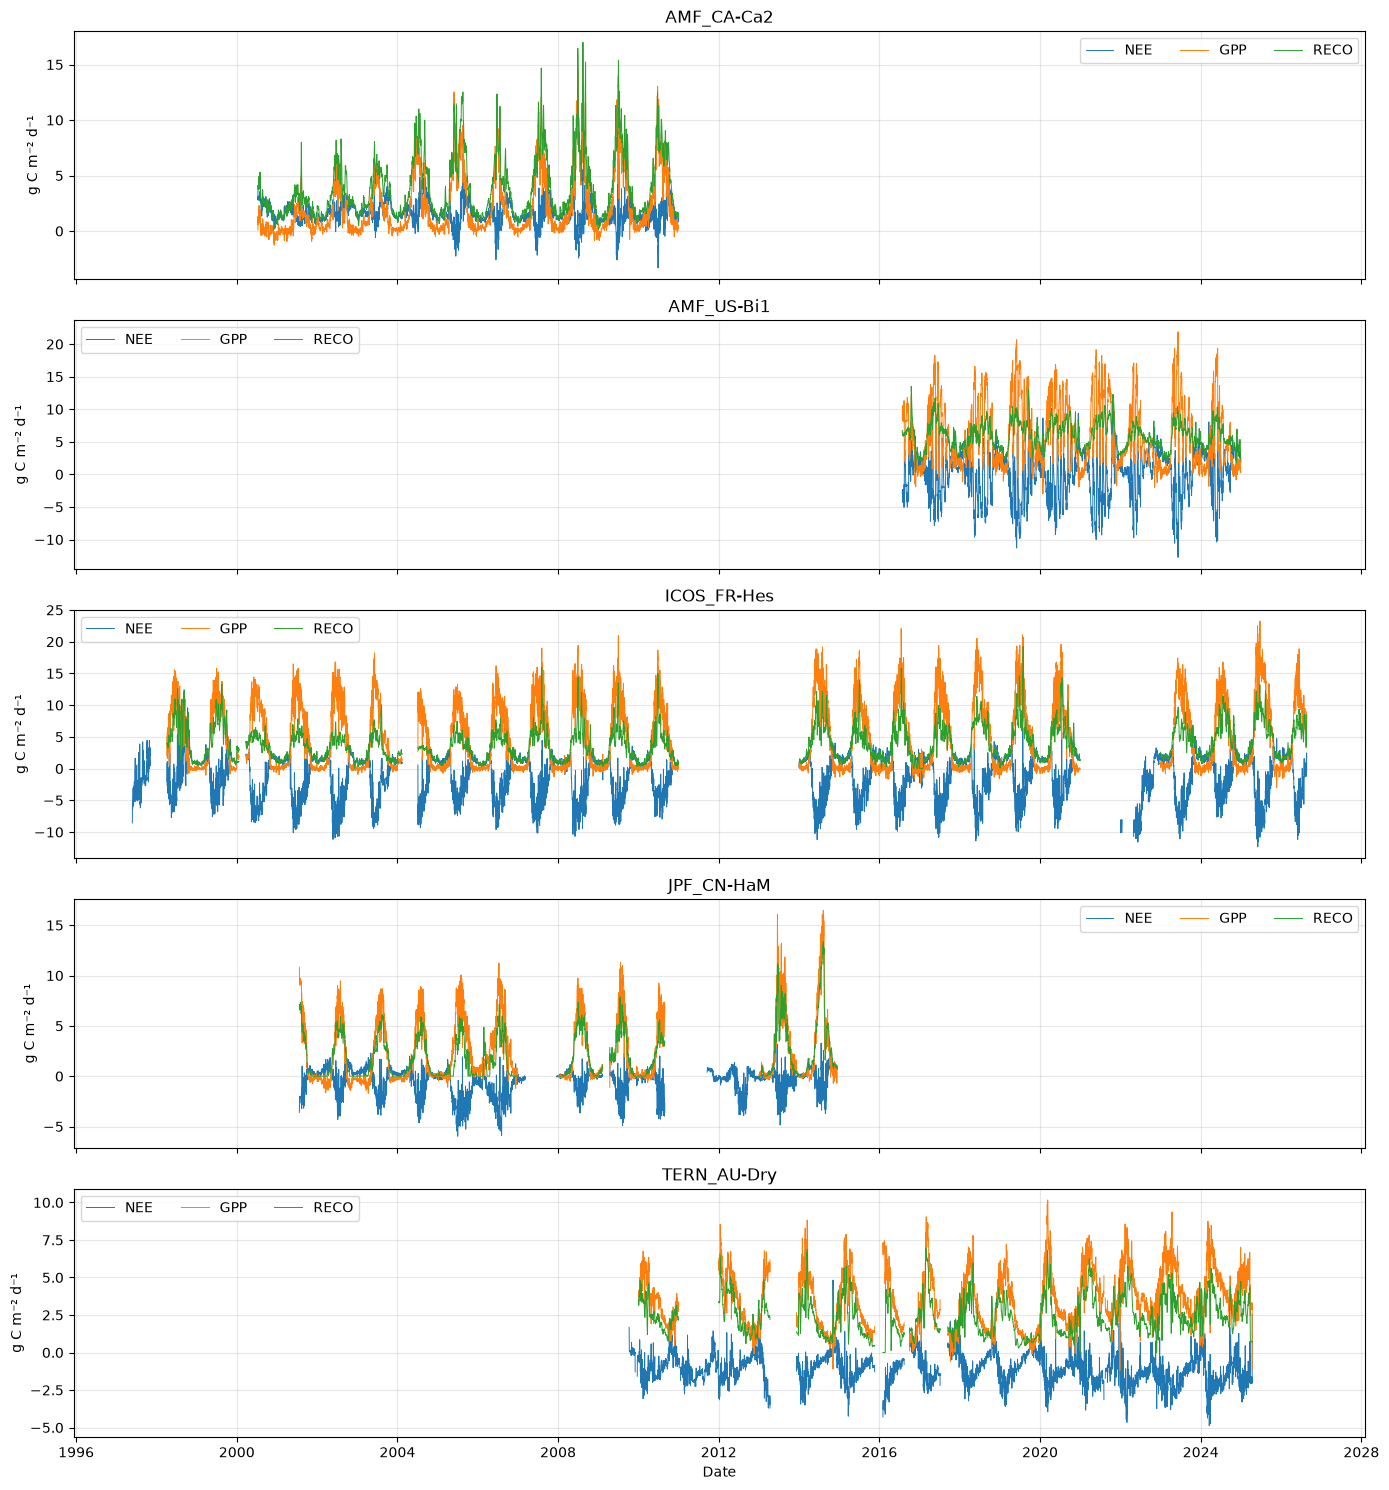

,variable,compared_days,mean_abs_difference_gC_m2_day
0,NEE_VUT_REF,3079,0.183338
1,GPP_NT_VUT_REF,3079,0.261414
2,RECO_NT_VUT_REF,3079,0.273047


In [58]:
flux_columns = ["NEE_VUT_REF", "GPP_NT_VUT_REF", "RECO_NT_VUT_REF"]
flux_labels = {
    "NEE_VUT_REF": "NEE",
    "GPP_NT_VUT_REF": "GPP",
    "RECO_NT_VUT_REF": "RECO",
}
conversion_factor = 1.0378

daily_fluxes = (
    master_df.set_index("time")
    .groupby("site")[flux_columns]
    .resample("D")
    .mean()
    .mul(conversion_factor)
    .reset_index()
)

sites = daily_fluxes["site"].unique()
fig, axes = plt.subplots(len(sites), 1, figsize=(14, 3 * len(sites)), sharex=True)
axes = np.atleast_1d(axes)

for ax, (site, data) in zip(axes, daily_fluxes.groupby("site", sort=True)):
    for column, label in flux_labels.items():
        ax.plot(data["time"], data[column], label=label, linewidth=0.7)
    ax.set_title(site)
    ax.set_ylabel("g C m⁻² d⁻¹")
    ax.legend(ncol=3)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Date")
fig.tight_layout()
plt.show()

# Compare the half-hourly aggregation with the daily file for one site.
check_site = "AMF_US-Bi1"
check_container = next(
    container for container in sorted(glob.glob(path + "*.zip"))
    if check_site in Path(container).name
)
with zipfile.ZipFile(check_container) as archive:
    daily_name = next(name for name in archive.namelist() if "FLUXMET_DD" in name)
    daily_reference = pd.read_csv(
        archive.open(daily_name),
        na_values=[-9999],
        usecols=lambda column: column == "TIMESTAMP" or column in flux_columns,
        dtype={"TIMESTAMP": str},
    )

daily_reference["time"] = pd.to_datetime(daily_reference["TIMESTAMP"], format="%Y%m%d")
daily_reference = (
    daily_reference.set_index("time")[flux_columns]
    .mul(conversion_factor)
    .rename(columns={column: f"{column}_DD" for column in flux_columns})
)
hourly_aggregation = (
    daily_fluxes.loc[daily_fluxes["site"].eq(check_site)]
    .set_index("time")[flux_columns]
    .rename(columns={column: f"{column}_HH" for column in flux_columns})
)
comparison = hourly_aggregation.join(daily_reference, how="inner")
comparison_summary = pd.DataFrame([
    {
        "variable": column,
        "compared_days": (comparison[f"{column}_HH"].notna() & comparison[f"{column}_DD"].notna()).sum(),
        "mean_abs_difference_gC_m2_day": (
            comparison[f"{column}_HH"] - comparison[f"{column}_DD"]
        ).abs().mean(),
    }
    for column in flux_columns
])
display(comparison_summary)

### C5. Diurnal cycles

The mean daily course (hour of day on the x-axis) of NEE and LE for each season, all five sites in one figure. Careful: seasons are reversed in the southern hemisphere. Use latitude to define the seasons correctly and say how you did it.



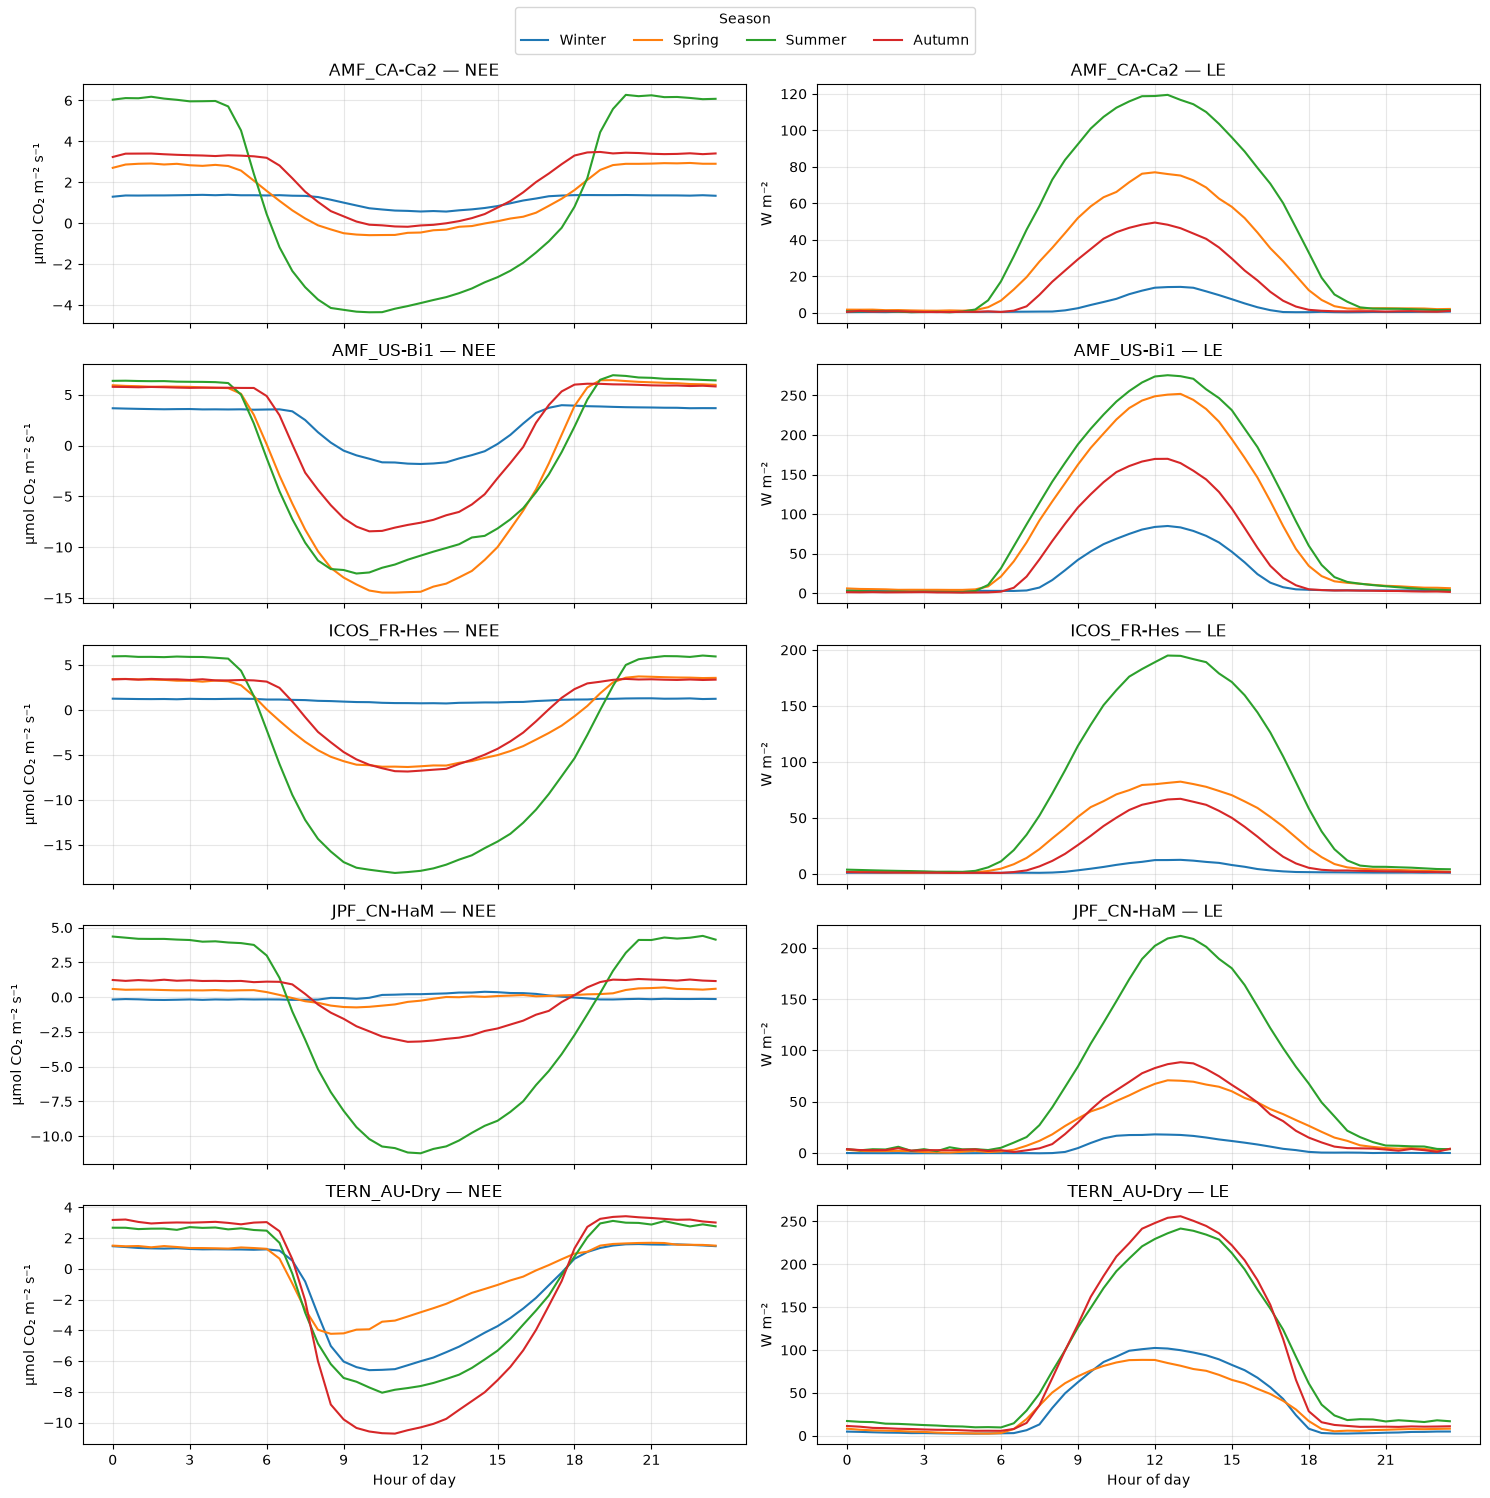

Seasons are meteorological: Northern Hemisphere winter = Dec–Feb, spring = Mar–May, summer = Jun–Aug, autumn = Sep–Nov; southern sites use the opposite seasons.


In [59]:
northern_season_by_month = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn",
}
opposite_season = {
    "Winter": "Summer",
    "Spring": "Autumn",
    "Summer": "Winter",
    "Autumn": "Spring",
}
season_order = ["Winter", "Spring", "Summer", "Autumn"]
season_colors = dict(zip(season_order, plt.rcParams["axes.prop_cycle"].by_key()["color"]))

diurnal_data = master_df[["site", "time", "NEE_VUT_REF", "LE_F_MDS"]].copy()
site_latitude = sites_df.set_index("site")["latitude"]
diurnal_data["latitude"] = diurnal_data["site"].map(site_latitude)
diurnal_data["season"] = diurnal_data["time"].dt.month.map(northern_season_by_month)
southern = diurnal_data["latitude"] < 0
diurnal_data.loc[southern, "season"] = diurnal_data.loc[southern, "season"].map(opposite_season)
diurnal_data["hour_of_day"] = (
    diurnal_data["time"].dt.hour + diurnal_data["time"].dt.minute / 60
)

diurnal_profile = (
    diurnal_data.groupby(["site", "season", "hour_of_day"])[["NEE_VUT_REF", "LE_F_MDS"]]
    .mean()
    .reset_index()
)

site_order = sites_df.sort_values("site")["site"].tolist()
fig, axes = plt.subplots(len(site_order), 2, figsize=(15, 3 * len(site_order)), sharex=True)

for row, site in enumerate(site_order):
    site_profile = diurnal_profile[diurnal_profile["site"].eq(site)]
    for season in season_order:
        seasonal_profile = site_profile[site_profile["season"].eq(season)]
        if seasonal_profile.empty:
            continue
        axes[row, 0].plot(
            seasonal_profile["hour_of_day"], seasonal_profile["NEE_VUT_REF"],
            label=season, color=season_colors[season],
        )
        axes[row, 1].plot(
            seasonal_profile["hour_of_day"], seasonal_profile["LE_F_MDS"],
            label=season, color=season_colors[season],
        )

    axes[row, 0].set_title(f"{site} — NEE")
    axes[row, 0].set_ylabel("µmol CO₂ m⁻² s⁻¹")
    axes[row, 1].set_title(f"{site} — LE")
    axes[row, 1].set_ylabel("W m⁻²")
    for ax in axes[row]:
        ax.set_xticks(range(0, 24, 3))
        ax.grid(True, alpha=0.3)

axes[-1, 0].set_xlabel("Hour of day")
axes[-1, 1].set_xlabel("Hour of day")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, title="Season", loc="upper center", ncol=4)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

print(
    "Seasons are meteorological: Northern Hemisphere winter = Dec–Feb, spring = Mar–May, "
    "summer = Jun–Aug, autumn = Sep–Nov; southern sites use the opposite seasons."
)

### C6. Your reading

1. **Energy balance** for one tower: scatter of `H_F_MDS + LE_F_MDS` against `NETRAD − G_F_MDS`, using only half hours where H and LE were measured (`_QC == 0`). Add the 1:1 line and the slope of a linear fit. Some towers have no `NETRAD` or `G`; pick one that has them.
2. **5–8 sentences** comparing your towers: which takes up the most carbon per year, which has the largest seasonal cycle, which surprised you, and how much of the data is gap-filled.

Close the report with a **Data and citation** section: each site's citation from the snapshot, Pastorello et al. (2020), *Scientific Data* 7, 225, <https://doi.org/10.1038/s41597-020-0534-3>, and the FLUXNET acknowledgement from `flux4student/README.md`.



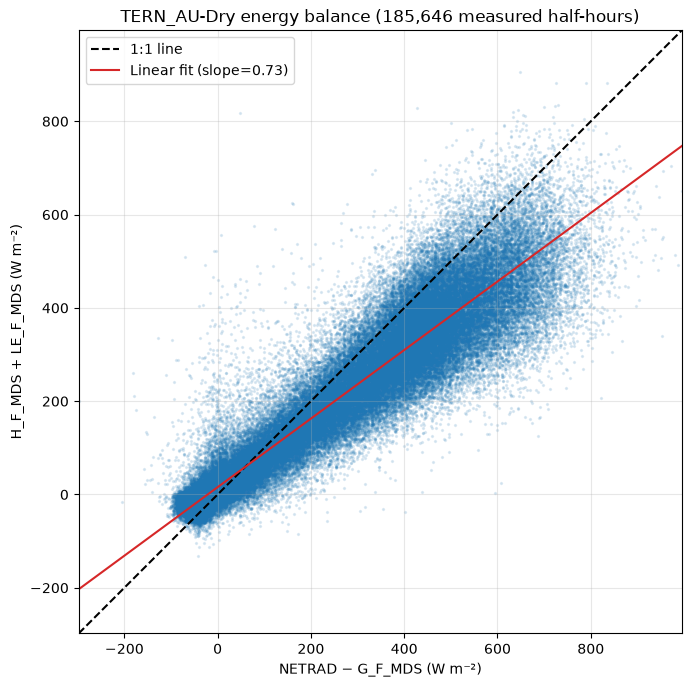

Using years with at least 90% valid daily NEE means, ICOS_FR-Hes had the strongest average net carbon uptake (-444 g C m⁻² yr⁻¹; negative NEE indicates uptake).
TERN_AU-Dry was the next strongest sink (-407 g C m⁻² yr⁻¹), while AMF_CA-Ca2 had the most positive mean annual NEE (+560 g C m⁻² yr⁻¹).
The largest seasonal NEE range, measured as the range of monthly climatological means, was at ICOS_FR-Hes (8.37 g C m⁻² d⁻¹).
Gap-filled NEE records ranged from 47.1% at ICOS_FR-Hes to 70.8% at AMF_US-Bi1, counting nonzero QC codes as gap-filled.
The energy-balance check uses 185,646 measured half-hours from TERN_AU-Dry; its fitted slope is 0.73, compared with an ideal slope of 1.
A notable contrast to discuss as a possible surprise is that AMF_CA-Ca2 is a net carbon source on average, while ICOS_FR-Hes is the strongest net sink.
Annual NEE values are sums of daily mean fluxes converted with 1.0378, averaged over years with at least 90% valid days.


## Data and citation

,Site,Data-product citation
0,AMF_CA-Ca2,"T. Andrew Black (2025), AmeriFlux FLUXNET-1F C..."
1,AMF_US-Bi1,"Camilo Rey-Sanchez, Carlos Tianxin Wang, Daphn..."
2,ICOS_FR-Hes,"Cuntz, M., Joetzjer, E., Aiguier, T., Courtois..."
3,JPF_CN-HaM,"Du, M., Gu, S., Kato, T., Li, Y., Liang, Z., Z..."
4,TERN_AU-Dry,"Beringer, J., Hutley, L., Northwood, M. (2026)..."


Pastorello et al. (2020), *Scientific Data* 7, 225. https://doi.org/10.1038/s41597-020-0534-3. Data licence: CC-BY-4.0.

> FLUXNET data products were produced and harmonized by eddy covariance regional networks and data processing centers, including AmeriFlux, ChinaFlux, European Fluxes Database, ICOS, JapanFlux, KoFlux, OzFlux, SAEON, and TERN. These products also include a modified version of ERA5 hourly data provided by the Copernicus Climate Change Service.

In [60]:
from IPython.display import Markdown, display

# Energy-balance check for the site with the most measured H/LE intervals.
energy_site = "TERN_AU-Dry"
energy = master_df.loc[
    master_df["site"].eq(energy_site)
    & master_df["H_F_MDS_QC"].eq(0)
    & master_df["LE_F_MDS_QC"].eq(0),
    ["NETRAD", "G_F_MDS", "H_F_MDS", "LE_F_MDS"],
].dropna().copy()
energy["available_energy"] = energy["NETRAD"] - energy["G_F_MDS"]
energy["turbulent_flux"] = energy["H_F_MDS"] + energy["LE_F_MDS"]
slope, intercept = np.polyfit(energy["available_energy"], energy["turbulent_flux"], 1)
line_limits = [
    min(energy["available_energy"].min(), energy["turbulent_flux"].min()),
    max(energy["available_energy"].max(), energy["turbulent_flux"].max()),
]

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(
    energy["available_energy"], energy["turbulent_flux"],
    s=2, alpha=0.12, rasterized=True,
)
ax.plot(line_limits, line_limits, "k--", label="1:1 line")
ax.plot(
    line_limits,
    [slope * value + intercept for value in line_limits],
    color="tab:red",
    label=f"Linear fit (slope={slope:.2f})",
)
ax.set(xlim=line_limits, ylim=line_limits, xlabel="NETRAD − G_F_MDS (W m⁻²)",
       ylabel="H_F_MDS + LE_F_MDS (W m⁻²)",
       title=f"{energy_site} energy balance ({len(energy):,} measured half-hours)")
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

# Compare site-level annual carbon balance and seasonal NEE range.
daily_nee = (
    master_df.set_index("time").groupby("site")["NEE_VUT_REF"]
    .resample("D").mean().mul(1.0378)
    .rename("nee_gC_m2_day").reset_index()
)
daily_nee["year"] = daily_nee["time"].dt.year
daily_nee["year_days"] = np.where(daily_nee["time"].dt.is_leap_year, 366, 365)
annual_nee = (
    daily_nee.groupby(["site", "year"], as_index=False)
    .agg(
        annual_nee_gC_m2=("nee_gC_m2_day", lambda values: values.sum(min_count=1)),
        valid_days=("nee_gC_m2_day", "count"),
        year_days=("year_days", "first"),
    )
)
annual_nee = annual_nee.loc[annual_nee["valid_days"] >= 0.9 * annual_nee["year_days"]]
mean_annual_nee = annual_nee.groupby("site")["annual_nee_gC_m2"].mean().sort_values()

monthly_nee = (
    master_df.set_index("time").groupby("site")["NEE_VUT_REF"]
    .resample("MS").mean().mul(1.0378)
    .rename("nee_gC_m2_day").reset_index()
)
monthly_nee["month"] = monthly_nee["time"].dt.month
monthly_climatology = monthly_nee.groupby(["site", "month"])["nee_gC_m2_day"].mean().reset_index()
seasonal_range = (
    monthly_climatology.groupby("site")["nee_gC_m2_day"]
    .agg(lambda values: values.max() - values.min())
    .sort_values(ascending=False)
)
gapfilled_percent = master_df.groupby("site")["NEE_VUT_REF_QC"].apply(
    lambda qc: 100 * qc.dropna().ne(0).mean()
).sort_values()

strongest_sink, second_sink = mean_annual_nee.index[:2]
largest_source = mean_annual_nee.index[-1]
largest_seasonal_range = seasonal_range.index[0]
least_gapfilled, most_gapfilled = gapfilled_percent.index[[0, -1]]
summary_sentences = [
    f"Using years with at least 90% valid daily NEE means, {strongest_sink} had the strongest average net carbon uptake ({mean_annual_nee.loc[strongest_sink]:.0f} g C m⁻² yr⁻¹; negative NEE indicates uptake).",
    f"{second_sink} was the next strongest sink ({mean_annual_nee.loc[second_sink]:.0f} g C m⁻² yr⁻¹), while {largest_source} had the most positive mean annual NEE ({mean_annual_nee.loc[largest_source]:+.0f} g C m⁻² yr⁻¹).",
    f"The largest seasonal NEE range, measured as the range of monthly climatological means, was at {largest_seasonal_range} ({seasonal_range.loc[largest_seasonal_range]:.2f} g C m⁻² d⁻¹).",
    f"Gap-filled NEE records ranged from {gapfilled_percent.loc[least_gapfilled]:.1f}% at {least_gapfilled} to {gapfilled_percent.loc[most_gapfilled]:.1f}% at {most_gapfilled}, counting nonzero QC codes as gap-filled.",
    f"The energy-balance check uses {len(energy):,} measured half-hours from {energy_site}; its fitted slope is {slope:.2f}, compared with an ideal slope of 1.",
    f"A notable contrast to discuss as a possible surprise is that {largest_source} is a net carbon source on average, while {strongest_sink} is the strongest net sink.",
    "Annual NEE values are sums of daily mean fluxes converted with 1.0378, averaged over years with at least 90% valid days.",
]
print("\n".join(summary_sentences))

display(Markdown("## Data and citation"))
display(sites_df[["site", "citation"]].rename(columns={"site": "Site", "citation": "Data-product citation"}))
display(Markdown(
    "Pastorello et al. (2020), *Scientific Data* 7, 225. "
    "https://doi.org/10.1038/s41597-020-0534-3. Data licence: CC-BY-4.0.\n\n"
    "> FLUXNET data products were produced and harmonized by eddy covariance regional networks and data processing centers, "
    "including AmeriFlux, ChinaFlux, European Fluxes Database, ICOS, JapanFlux, KoFlux, OzFlux, SAEON, and TERN. "
    "These products also include a modified version of ERA5 hourly data provided by the Copernicus Climate Change Service."
))

- [ ] It renders from a fresh clone with the commands in your README
